# Wind geometry from saved likelihood profiles

Both scans profile the continuum normalization and the remaining free geometry
coordinates. The native plane is $(i,C_f)$; the physical plane is
$(\theta_{\rm out},\theta_{\rm in})$, where
$C_f=\cos\theta_{\rm in}-\cos\theta_{\rm out}$.
These are different profile planes, not a relabelling of one surface.

Generate the FITS files with the commands in `../README.md`, then run this
notebook from `results/`. Change the two paths below to inspect other scans.
The levels are the usual joint two-parameter 1, 2 and 3-sigma likelihood
thresholds. No smoothing or interpolation is applied across excluded cells.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from xspeclab.steppar import StepparData
from xspeclab.confidence import sigma2deltachi

native = StepparData("incl-cf.fits")
angles = StepparData("tout-tin.fits")
native.make_matrix()
angles.make_matrix()
levels = sigma2deltachi(sigma=[1, 2, 3], dof=2)
colors = ["tab:red", "tab:green", "tab:blue"]


The cross marks the **lowest sampled grid value**, not a continuous best-fit
estimate. The angular triangle is excluded by geometry, not assigned a zero
statistic. Dashed grey curves indicate constant hemispheric covering fraction.

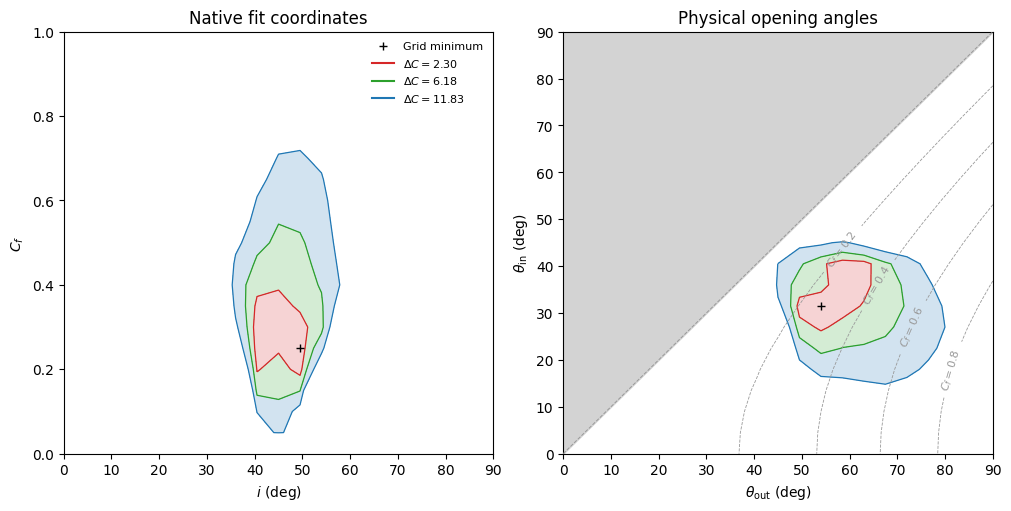

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
labels = [(r"$i$ (deg)", r"$C_f$"),
          (r"$\theta_{\rm out}$ (deg)", r"$\theta_{\rm in}$ (deg)")]
for scan, ax, (xlabel, ylabel) in zip([native, angles], axes, labels):
    delta = np.ma.masked_invalid(scan.deltastat)
    ax.contourf(scan.x, scan.y, delta, levels=np.r_[0, levels],
                colors=colors, alpha=0.2, corner_mask=False)
    ax.contour(scan.x, scan.y, delta, levels=levels,
               colors=colors, linewidths=0.9, corner_mask=False)
    row, column = np.unravel_index(np.nanargmin(scan.stat), scan.stat.shape)
    ax.plot(scan.x[column], scan.y[row], "+", color="black", label="Grid minimum", zorder=4)
    ax.set(xlabel=xlabel, ylabel=ylabel,
           xlim=(scan.x.min(), scan.x.max()), ylim=(scan.y.min(), scan.y.max()))

# Geometric relation, evaluated independently of the fit statistic.
tout, tin = np.meshgrid(angles.x, angles.y)
cover = np.ma.masked_where(tin > tout,
    np.cos(np.deg2rad(tin)) - np.cos(np.deg2rad(tout)))
curves = axes[1].contour(angles.x, angles.y, cover, levels=[0.2, 0.4, 0.6, 0.8],
                         colors="0.6", linewidths=0.6, linestyles="--", corner_mask=False)
axes[1].clabel(curves, fmt=lambda value: f"$C_f={value:.1f}$", fontsize=8)
axes[1].fill_between([0, 90], [0, 90], [90, 90], color="lightgrey", zorder=-10)
axes[1].plot([0, 90], [0, 90], "--", color="0.6", linewidth=0.7, zorder=4)
for level, color in zip(levels, colors):
    axes[0].plot([], [], color=color, label=fr"$\Delta C={level:.2f}$")
axes[0].legend(frameon=False, fontsize=8)
axes[0].set_title("Native fit coordinates")
axes[1].set_title("Physical opening angles")
fig.savefig("geometry.png", dpi=180)
fig.savefig("geometry.pdf")
plt.show()
